# Predicción precios de vehículos

**Autor:** Lucas Faura Martín

**Entorno:** Python 3 / Google Colab  

[Ver vídeo de la presentación en YouTube](https://youtu.be/iaX2wkZrpmE)
---

### 1. Descripción del Proyecto
Este proyecto realiza un análisis de datos y desarrollo de modelos predictivos sobre un conjunto de datos de automóviles del año 2025 (`CarsDatasets2025.csv`). El objetivo principal es determinar los factores clave que influyen en el valor monetario de un vehículo y construir un modelo capaz de estimar su precio final a partir de sus especificaciones técnicas y tipo de combustible.

### 2. Objetivos
* **Limpiar y estructurar:** Procesar variables numéricas expresadas como cadenas o rangos, estandarizar los tipos de combustible y tratar adecuadamente valores nulos u *outliers*.
* **Analizar patrones (EDA):** Evaluar la correlación entre la potencia (`horsepower`), el tipo de combustible (`fuel_types`), la cilindrada y el precio comercial (`cars_prices`).
* **Modelar y Predecir:** Entrenar y evaluar modelos de regresión (Regresión Lineal, Árboles de Decisión y Random Forest) para predecir el valor de la variable objetivo.

### 3. Metodología
1. **Limpieza y Transformación:** Extracción de datos numéricos con expresiones regulares (`extraer_numero`), reestructuración de la columna de combustibles e imputación de nulos por mediana.
2. **Análisis Exploratorio de Datos:** Histograma de distribución del precio e hipergráficos de dispersión entre potencia y precio segmentados por combustible.
3. **Preprocesamiento:** Escalado de variables numéricas (`StandardScaler`) y codificación categórica (`OneHotEncoder`) estructurados mediante `Pipeline` y `ColumnTransformer`.
4. **Evaluación de Modelos:** Comparativa de rendimiento utilizando métricas de regresión ($R^2$, MAE, RMSE) sobre el conjunto de validación.

## Obtención de datos

Los datos están contenidos en el fichero `CarsDatasets2025.csv`.

In [ ]:
# 1. Limpieza de datos y manipulación
import re
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
# 2. Visualización de datos
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# 3. Machine Learning y Preprocesamiento (scikit-learn)
from sklearn.model_selection import (
    GridSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

In [ ]:
ruta_archivo = '/content/drive/MyDrive/datasets/CarsDatasets2025.csv'
ds_coches = pd.read_csv(ruta_archivo, encoding='latin1')

## Exploración y visualización de los datos

In [ ]:
ds_coches.head()

,Company Names,Cars Names,Engines,CC/Battery Capacity,HorsePower,Total Speed,Performance(0 - 100 )KM/H,Cars Prices,Fuel Types,Seats,Torque
0,FERRARI,SF90 STRADALE,V8,3990 cc,963 hp,340 km/h,2.5 sec,"$1,100,000",plug in hyrbrid,2,800 Nm
1,ROLLS ROYCE,PHANTOM,V12,6749 cc,563 hp,250 km/h,5.3 sec,"$460,000",Petrol,5,900 Nm
2,Ford,KA+,1.2L Petrol,"1,200 cc",70-85 hp,165 km/h,10.5 sec,"$12,000-$15,000",Petrol,5,100 - 140 Nm
3,MERCEDES,GT 63 S,V8,"3,982 cc",630 hp,250 km/h,3.2 sec,"$161,000",Petrol,4,900 Nm
4,AUDI,AUDI R8 Gt,V10,"5,204 cc",602 hp,320 km/h,3.6 sec,"$253,290",Petrol,2,560 Nm


In [ ]:
# Renombrar columnas para facilitar su manipulación
ds_coches.columns = [
    c.strip().lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
    for c in ds_coches.columns
]

print("--- INFORMACIÓN GENERAL DEL DATASET ---")
print(ds_coches.info())

print("\n--- VALORES NULOS POR COLUMNA ---")
print(ds_coches.isnull().sum())

print("\n--- PRIMERAS FILAS CON NOMBRES NORMALIZADOS ---")
ds_coches.head()

--- INFORMACIÓN GENERAL DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   company_names            1218 non-null   object
 1   cars_names               1218 non-null   object
 2   engines                  1218 non-null   object
 3   cc/battery_capacity      1215 non-null   object
 4   horsepower               1218 non-null   object
 5   total_speed              1218 non-null   object
 6   performance0___100_km/h  1212 non-null   object
 7   cars_prices              1218 non-null   object
 8   fuel_types               1218 non-null   object
 9   seats                    1218 non-null   object
 10  torque                   1217 non-null   object
dtypes: object(11)
memory usage: 104.8+ KB
None

--- VALORES NULOS POR COLUMNA ---
company_names              0
cars_names                 0
engines                

,company_names,cars_names,engines,cc/battery_capacity,horsepower,total_speed,performance0___100_km/h,cars_prices,fuel_types,seats,torque
0,FERRARI,SF90 STRADALE,V8,3990 cc,963 hp,340 km/h,2.5 sec,"$1,100,000",plug in hyrbrid,2,800 Nm
1,ROLLS ROYCE,PHANTOM,V12,6749 cc,563 hp,250 km/h,5.3 sec,"$460,000",Petrol,5,900 Nm
2,Ford,KA+,1.2L Petrol,"1,200 cc",70-85 hp,165 km/h,10.5 sec,"$12,000-$15,000",Petrol,5,100 - 140 Nm
3,MERCEDES,GT 63 S,V8,"3,982 cc",630 hp,250 km/h,3.2 sec,"$161,000",Petrol,4,900 Nm
4,AUDI,AUDI R8 Gt,V10,"5,204 cc",602 hp,320 km/h,3.6 sec,"$253,290",Petrol,2,560 Nm


## Limpieza de datos

In [ ]:
# Copia de trabajo para mantener el dataset original intacto
df_clean = ds_coches.copy()


# 1. Función para extraer números y calcular promedios si existen rangos (ej. '12,000-15,000' -> 13500)
def extraer_numero(val):
  if pd.isna(val):
    return np.nan
  val = str(val).replace(',', '').strip()
  # Buscar rangos numéricos tipo X - Y o X-Y
  rango = re.findall(r'(\d+\.?\d*)\s*-\s*(\d+\.?\d*)', val)
  if rango:
    num1, num2 = float(rango[0][0]), float(rango[0][1])
    return (num1 + num2) / 2
  # Buscar número individual (entero o decimal)
  num = re.findall(r'(\d+\.?\d*)', val)
  if num:
    return float(num[0])
  return np.nan


# 2. Aplicar la extracción a las columnas numéricas
columnas_numericas = [
    'cc/battery_capacity',
    'horsepower',
    'total_speed',
    'performance0___100_km/h',
    'cars_prices',
    'seats',
    'torque',
]

for col in columnas_numericas:
  df_clean[col] = df_clean[col].apply(extraer_numero)

# 3. Limpieza de nombres de marcas y tipos de combustible
df_clean['company_names'] = df_clean['company_names'].str.upper().str.strip()
df_clean['fuel_types'] = df_clean['fuel_types'].str.capitalize().str.strip()


# 4. Agrupación de combustibles guardada directamente en el dataset
def agrupar_combustible(comb):
  comb = str(comb).lower()
  if 'electric' in comb or 'ev' in comb:
    return 'Electric'
  elif 'plug-in' in comb or 'plugin' in comb or 'plug' in comb:
    return 'Plug-in Hybrid'
  elif 'hybrid' in comb:
    return 'Hybrid'
  elif 'diesel' in comb:
    return 'Diesel'
  elif 'petrol' in comb or 'gas' in comb:
    return 'Petrol'
  else:
    return 'Other'


df_clean['fuel_grouped'] = df_clean['fuel_types'].apply(agrupar_combustible)

# 5. Imputación de nulos restantes con la mediana según la categoría
for col in ['cc/battery_capacity', 'performance0___100_km/h', 'torque']:
  df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 6. Filtrar el coche con potencia errónea/outlier (mayor a 2.000 hp)
df_clean = df_clean[df_clean['horsepower'] <= 2000].reset_index(drop=True)

print('--- RESUMEN TRAS LA LIMPIEZA ---')
print(df_clean[columnas_numericas].info())
print('\n--- ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS ---')
df_clean[columnas_numericas].describe()

--- RESUMEN TRAS LA LIMPIEZA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217 entries, 0 to 1216
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   cc/battery_capacity      1217 non-null   float64
 1   horsepower               1217 non-null   float64
 2   total_speed              1217 non-null   float64
 3   performance0___100_km/h  1217 non-null   float64
 4   cars_prices              1216 non-null   float64
 5   seats                    1217 non-null   float64
 6   torque                   1217 non-null   float64
dtypes: float64(7)
memory usage: 66.7 KB
None

--- ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS ---


,cc/battery_capacity,horsepower,total_speed,performance0___100_km/h,cars_prices,seats,torque
count,1217.000000,1217.000000,1217.000000,1217.000000,1.216000e+03,1217.000000,1217.000000
mean,2748.441495,305.508628,216.529992,7.559532,1.368572e+05,4.824979,506.832375
std,1935.019418,213.910178,53.027528,3.298217,7.051622e+05,1.493880,1049.516701
min,1.240000,26.000000,80.000000,1.900000,4.000000e+03,1.000000,45.000000
25%,1560.000000,152.000000,180.000000,5.300000,2.787375e+04,4.000000,250.000000
50%,2000.000000,251.500000,200.000000,7.100000,4.200000e+04,5.000000,370.000000
75%,3564.000000,400.000000,250.000000,9.500000,7.000000e+04,5.000000,560.000000
max,16100.000000,1850.000000,500.000000,35.000000,1.800000e+07,20.000000,15590.000000


In [ ]:
# Eliminar la fila con precio nulo (target)
df_clean = df_clean.dropna(subset=['cars_prices']).reset_index(drop=True)

# Estilo visual de las gráficas
sns.set_theme(style="whitegrid")

## Visualización de datos en gráficas

### Gráfica 1: Distribución según precio

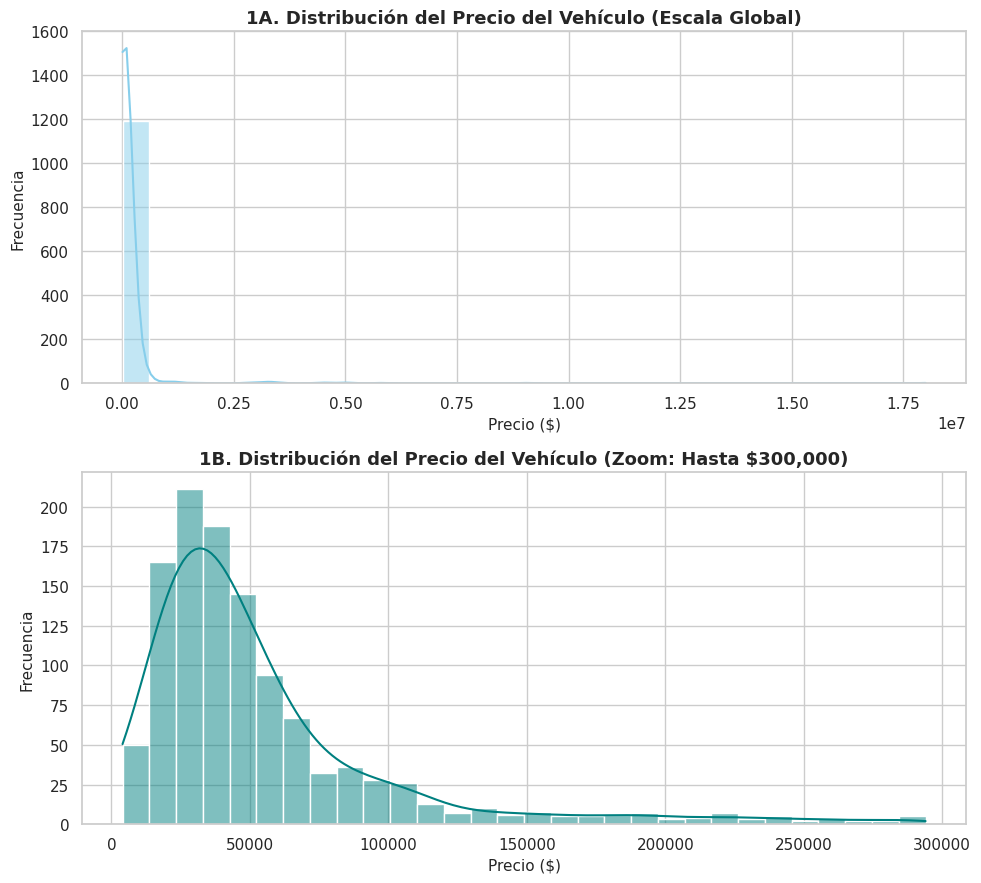

In [ ]:
# Crear una figura con 2 subgráficas
fig, axes = plt.subplots(2, 1, figsize=(10, 9))

# 1. Gráfica Global (Escala completa)
sns.histplot(df_clean['cars_prices'], kde=True, color='skyblue', bins=30, ax=axes[0])
axes[0].set_title('1A. Distribución del Precio del Vehículo (Escala Global)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Precio ($)', fontsize=11)
axes[0].set_ylabel('Frecuencia', fontsize=11)

# 2. Gráfica Zoom (Filtrando vehículos de hasta $300,000)
df_zoom = df_clean[df_clean['cars_prices'] <= 300000]
sns.histplot(df_zoom['cars_prices'], kde=True, color='teal', bins=30, ax=axes[1])
axes[1].set_title('1B. Distribución del Precio del Vehículo (Zoom: Hasta $300,000)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Precio ($)', fontsize=11)
axes[1].set_ylabel('Frecuencia', fontsize=11)

plt.tight_layout()
plt.show()

### Gráfica 2: Potencia vs Precio

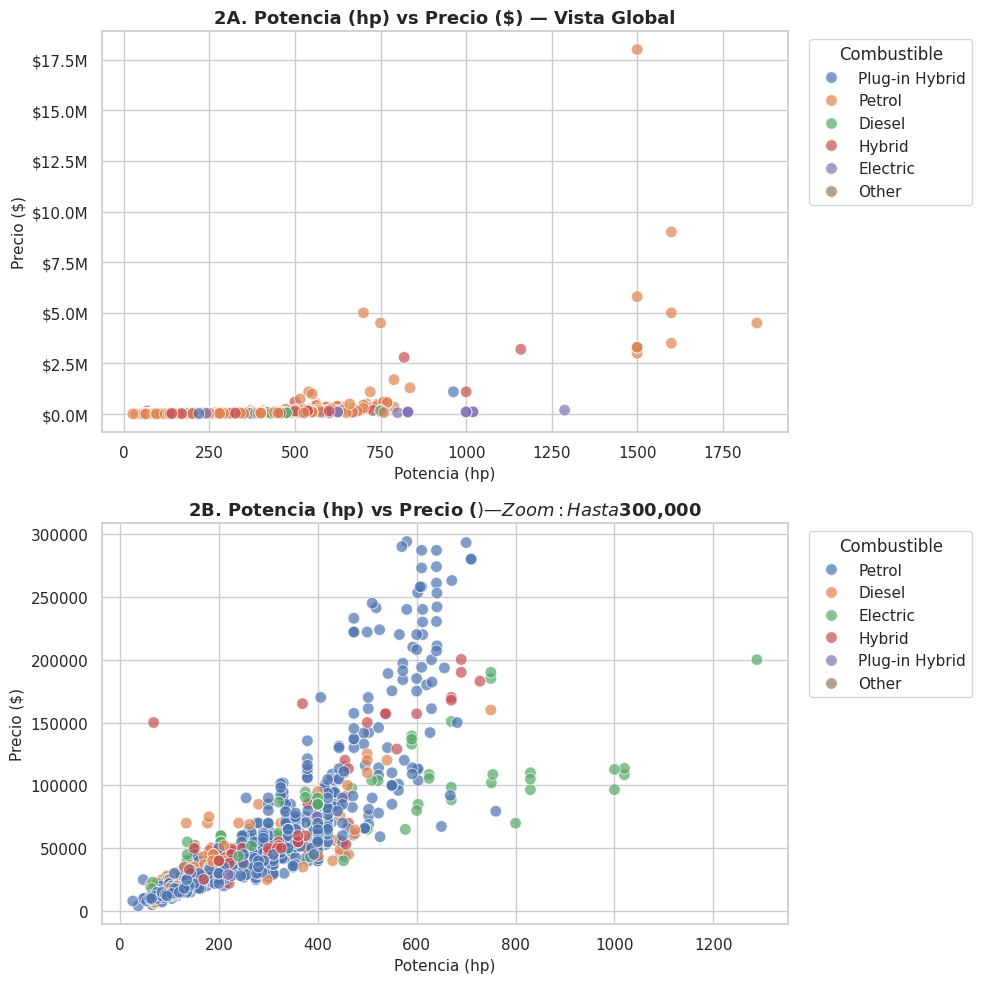

In [ ]:
# Crear figura con 2 subgráficas
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# 2A. Vista Global (Con outliers de superdeportivos)
sns.scatterplot(
    data=df_clean,
    x='horsepower',
    y='cars_prices',
    hue='fuel_grouped',
    alpha=0.7,
    s=70,
    ax=axes[0],
)
axes[0].set_title(
    '2A. Potencia (hp) vs Precio ($) — Vista Global',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Potencia (hp)', fontsize=11)
axes[0].set_ylabel('Precio ($)', fontsize=11)
axes[0].legend(
    bbox_to_anchor=(1.02, 1), loc='upper left', title='Combustible'
)

# Formatear el eje Y de la gráfica global a formato $M
axes[0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'${x*1e-6:.1f}M')
)

# 2B. Vista Zoom (Coches hasta $300,000)
df_zoom_g2 = df_clean[df_clean['cars_prices'] <= 300000]
sns.scatterplot(
    data=df_zoom_g2,
    x='horsepower',
    y='cars_prices',
    hue='fuel_grouped',
    alpha=0.7,
    s=70,
    ax=axes[1],
)
axes[1].set_title(
    '2B. Potencia (hp) vs Precio ($) — Zoom: Hasta $300,000',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Potencia (hp)', fontsize=11)
axes[1].set_ylabel('Precio ($)', fontsize=11)
axes[1].legend(
    bbox_to_anchor=(1.02, 1), loc='upper left', title='Combustible'
)

plt.tight_layout()
plt.show()

### Gráfica 3: Precios según marcas

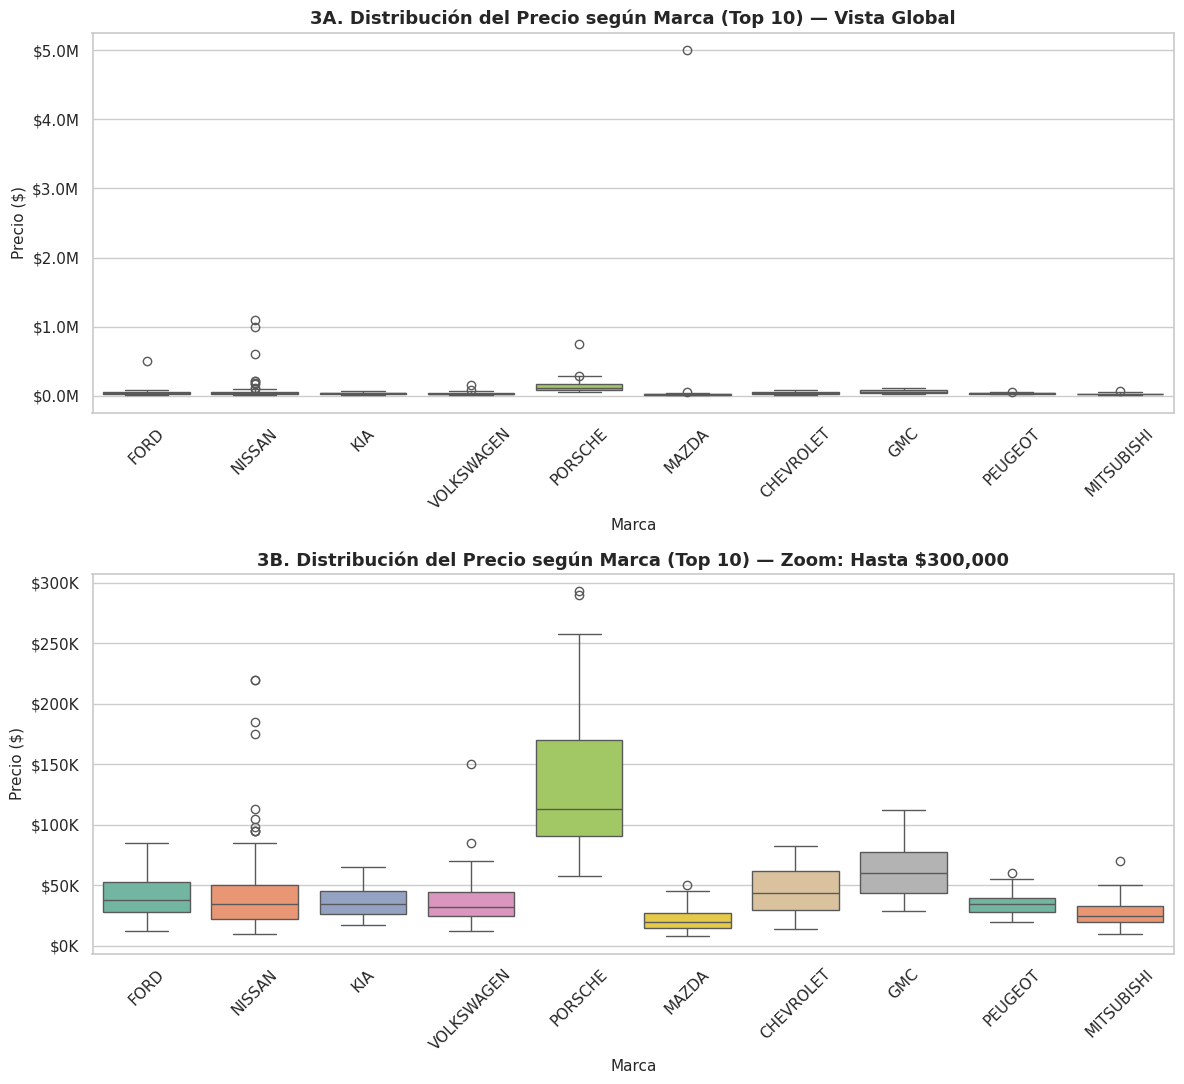

In [ ]:
# 1. Seleccionar las 10 marcas con más vehículos para mantener la gráfica legible
top_marcas = df_clean['company_names'].value_counts().head(10).index
df_top_marcas = df_clean[df_clean['company_names'].isin(top_marcas)]

# 2. Crear figura con 2 subgráficas (Vista Global y Zoom)
fig, axes = plt.subplots(2, 1, figsize=(12, 11))

# 3A. Vista Global (Formato en Millones $M)
sns.boxplot(
    data=df_top_marcas,
    x='company_names',
    y='cars_prices',
    hue='company_names',
    palette='Set2',
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    '3A. Distribución del Precio según Marca (Top 10) — Vista Global',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Marca', fontsize=11)
axes[0].set_ylabel('Precio ($)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'${x*1e-6:.1f}M')
)

# 3B. Vista Zoom (Coches hasta $300,000 con formato en Miles $K)
df_zoom_g3 = df_top_marcas[df_top_marcas['cars_prices'] <= 300000]

sns.boxplot(
    data=df_zoom_g3,
    x='company_names',
    y='cars_prices',
    hue='company_names',
    palette='Set2',
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    '3B. Distribución del Precio según Marca (Top 10) — Zoom: Hasta $300,000',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Marca', fontsize=11)
axes[1].set_ylabel('Precio ($)', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'${x*1e-3:.0f}K')
)

plt.tight_layout()
plt.show()

### Matriz de Correlación: Especificaciones Técnicas y Precio

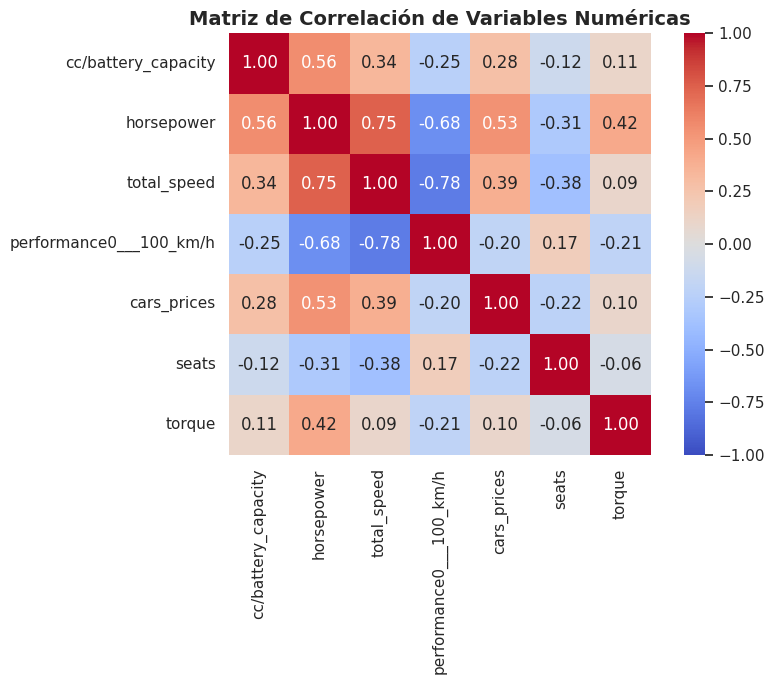

In [ ]:
plt.figure(figsize=(9, 7))
corr = df_clean[columnas_numericas].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=True, square=True)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Matriz de Correlación Triangular: Variables Numéricas

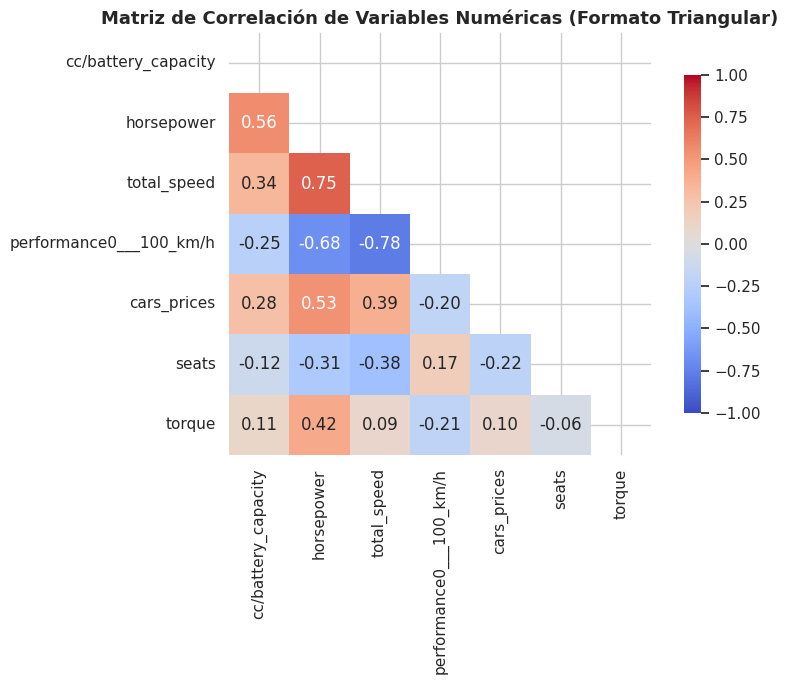

In [ ]:
# 1. Calcular la matriz de correlación de tus variables numéricas
corr = df_clean[columnas_numericas].corr()

# 2. Crear una máscara para ocultar la diagonal superior duplicada
mask = np.triu(np.ones_like(corr, dtype=bool))

# 3. Dibujar el mapa de calor en formato triangular
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title('Matriz de Correlación de Variables Numéricas (Formato Triangular)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Preparación de los datos para los algoritmos de Machine Learning

Se filtran los valores atípicos extremados, se define la variable objetivo en escala logarítmica (`y_log`) para estabilizar la varianza, se realiza la partición del dataset (80% entrenamiento / 20% prueba) y se configura el preprocesador genérico (`ColumnTransformer`) para las variables numéricas y categóricas.

In [ ]:
# 1. Filtrar hiperdeportivos atípicos (> $500,000)
df_ml = df_clean[df_clean['cars_prices'] <= 500000].copy()

# 2. Barajamos los datos para evitar datos similares continuos
df_ml = df_ml.sample(frac=1, random_state=42).reset_index(drop=True)

# 3. Definir variables de entrada (X) y objetivo logarítmica (y_log)
feature_cols_num = [
    'cc/battery_capacity',
    'horsepower',
    'total_speed',
    'performance0___100_km/h',
    'seats',
    'torque',
]
feature_cols_cat = ['company_names', 'fuel_grouped']

X = df_ml[feature_cols_num + feature_cols_cat]
y_log = np.log1p(df_ml['cars_prices'])

# 4. División en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.20, random_state=42
)

# 5. Pipeline de preprocesamiento (escalado + codificación one-hot)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_cols_num),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            feature_cols_cat,
        ),
    ]
)

print(f'Muestras de entrenamiento: {X_train.shape[0]}')
print(f'Muestras de prueba (test): {X_test.shape[0]}')

Muestras de entrenamiento: 948
Muestras de prueba (test): 238


## Entrenamiento del modelo y comprobación del rendimiento

### Validación cruzada (cross-validation)

La validación cruzada es una técnica que permite evaluar la capacidad de generalización de un modelo de forma más fiable que utilizando una única división de los datos.

Funciona de la siguiente manera:
1. Se divide el conjunto de entrenamiento en K partes de tamaño aproximadamente igual.
2. Se entrena el modelo utilizando K-1 partes y se evalúa con la parte restante.
3. Se repite el proceso K veces, utilizando cada vez una parte diferente para la validación.
4. Se calcula la media de las métricas obtenidas en las K evaluaciones.

Por ejemplo, si utilizamos K = 3, el modelo se entrena tres veces, utilizando en cada ocasión 2/3 de los datos para entrenar y 1/3 restante para validar.

La validación cruzada permite comparar diferentes modelos y ajustar sus hiperparámetros sin utilizar el conjunto de prueba (test).

In [ ]:
# Definimos el modelo base lineal dentro de un Pipeline con el preprocesador
model_lineal = Pipeline(
    steps=[('preprocessor', preprocessor), ('model', LinearRegression())]
)


def evaluar_cv(modelo_pipeline, nombre):
  # Evaluamos mediante validación cruzada con 3 particiones
  puntuaciones = cross_validate(
      modelo_pipeline,
      X_train,
      y_train_log,
      cv=3,
      scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
  )

  # Scikit-learn devuelve RMSE negativo; le invertimos el signo
  rmse = -puntuaciones['test_rmse'].mean()
  r2 = puntuaciones['test_r2'].mean()

  print(f'--- {nombre} ---')
  print(f'RMSE medio (validación cruzada - log): {rmse:.4f}')
  print(f'R² medio (validación cruzada): {r2:.3f}\n')

  return {'Modelo': nombre, 'RMSE CV': rmse, 'R² CV': r2}


resultados_cv = []
resultados_cv.append(evaluar_cv(model_lineal, 'Regresión lineal'))

--- Regresión lineal ---
RMSE medio (validación cruzada - log): 0.2650
R² medio (validación cruzada): 0.892



### Árboles de decisión

In [ ]:
# Instancia y entrenamiento del Pipeline con el Árbol de Decisión
modelo_arbol = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(random_state=42)),
    ]
)

modelo_arbol.fit(X_train, y_train_log)

# Predicciones sobre el conjunto de entrenamiento reconvertidas a dólares reales ($)
y_pred_train_log = modelo_arbol.predict(X_train)
y_train_real = np.expm1(y_train_log).to_list()
y_pred_train_real = np.expm1(y_pred_train_log)

print("Prec. real ($)    Prec. estimado ($)    Error absoluto ($) (entrenamiento)")
for i in range(min(20, len(y_train_real))):
  r = y_train_real[i]
  e = y_pred_train_real[i]
  e_abs = abs(r - e)
  print(f"{r:13.2f}   {e:16.2f}   {e_abs:20.2f}")

# Aplicamos validación cruzada al árbol de decisión
resultados_cv.append(evaluar_cv(modelo_arbol, "Árbol de decisión"))

Prec. real ($)    Prec. estimado ($)    Error absoluto ($) (entrenamiento)
     53000.00           53000.00                   0.00
     28505.00           28505.00                   0.00
    207000.00          207000.00                   0.00
    113300.00          114642.05                1342.05
     80000.00           80000.00                   0.00
     27000.00           27000.00                   0.00
    175200.00          175200.00                   0.00
     36100.00           36100.00                   0.00
     28000.00           28000.00                   0.00
     35000.00           35000.00                   0.00
     70000.00           70000.00                   0.00
    110000.00          110000.00                   0.00
     65895.00           65895.00                   0.00
     31000.00           30284.70                 715.30
     50000.00           46904.16                3095.84
    350000.00          387351.17               37351.17
     45000.00           45000

### Random forest

In [ ]:
# Instancia y entrenamiento del Pipeline con Random Forest
modelo_bosque = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(n_estimators=100, random_state=42)),
    ]
)

modelo_bosque.fit(X_train, y_train_log)

# Predicciones sobre el conjunto de entrenamiento reconvertidas a dólares reales ($)
y_pred_train_log = modelo_bosque.predict(X_train)
y_train_real = np.expm1(y_train_log).to_list()
y_pred_train_real = np.expm1(y_pred_train_log)

print("Prec. real ($)    Prec. estimado ($)    Error absoluto ($) (entrenamiento)")
for i in range(min(20, len(y_train_real))):
  r = y_train_real[i]
  e = y_pred_train_real[i]
  e_abs = abs(r - e)
  print(f"{r:13.2f}   {e:16.2f}   {e_abs:20.2f}")

# Aplicamos la validación cruzada a Random Forest
resultados_cv.append(evaluar_cv(modelo_bosque, "Random forest"))

# Comparativa provisional de modelos
display(pd.DataFrame(resultados_cv).round(4))

Prec. real ($)    Prec. estimado ($)    Error absoluto ($) (entrenamiento)
     53000.00           53050.92                  50.92
     28505.00           30277.25                1772.25
    207000.00          219125.69               12125.69
    113300.00          114524.96                1224.96
     80000.00           72765.17                7234.83
     27000.00           31444.84                4444.84
    175200.00          174798.46                 401.54
     36100.00           32868.89                3231.11
     28000.00           28614.09                 614.09
     35000.00           33445.27                1554.73
     70000.00           63037.87                6962.13
    110000.00          105164.85                4835.15
     65895.00           85674.98               19779.98
     31000.00           30469.39                 530.61
     50000.00           47535.44                2464.56
    350000.00          384600.38               34600.38
     45000.00           45755

,Modelo,RMSE CV,R² CV
0,Regresión lineal,0.2650,0.8918
1,Árbol de decisión,0.2795,0.8763
2,Random forest,0.2324,0.9154


### Ajuste de hiperparámetros

Hemos entrenado tres modelos. Ahora intentaremos mejorar el bosque aleatorio (Random Forest) sin utilizar el conjunto de prueba.

Un parámetro es un valor que el algoritmo aprende a partir de los datos. Un hiperparámetro se establece antes del entrenamiento y controla cómo aprende el modelo. En este caso ajustaremos:
- `n_estimators`: número de árboles del bosque.
- `max_depth`: profundidad máxima de los árboles.
- `min_samples_leaf`: número mínimo de muestras por hoja.

#### GridSearchCV: búsqueda en una rejilla
`GridSearchCV` prueba todas las combinaciones de una pequeña rejilla de hiperparámetros y elige la que obtiene menor RMSE mediante validación cruzada.

Para que esta práctica no sea demasiado lenta, buscaremos hiperparámetros sobre una muestra aleatoria del conjunto de entrenamiento. Después comprobaremos el modelo ajustado con validación cruzada sobre todo el conjunto de entrenamiento y lo volveremos a entrenar con todos esos datos. El conjunto de prueba permanece reservado.

In [ ]:
# 1. Definimos una muestra de entrenamiento adaptada al tamaño real del dataset
n_muestras = min(5000, len(X_train))
X_busqueda = X_train.sample(n=n_muestras, random_state=42)
y_busqueda = y_train_log.loc[X_busqueda.index]

pipeline_grid = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=42, n_jobs=-1)),
    ]
)

rejilla = {
    'model__n_estimators': [20, 40],
    'model__max_depth': [None, 20],
    'model__min_samples_leaf': [1, 3],
}

busqueda_grid = GridSearchCV(
    pipeline_grid,
    param_grid=rejilla,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
busqueda_grid.fit(X_busqueda, y_busqueda)

mejores_params = {
    k.replace('model__', ''): v for k, v in busqueda_grid.best_params_.items()
}
print('Mejores hiperparámetros:', mejores_params)
print(
    f'RMSE CV durante la búsqueda (log): {-busqueda_grid.best_score_:.4f}'
)

# 2. Comparamos el modelo ajustado con CV sobre todo X_train
modelo_bosque_ajustado = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                **mejores_params, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

resultados_cv.append(
    evaluar_cv(modelo_bosque_ajustado, 'Random Forest ajustado')
)
modelo_bosque_ajustado.fit(X_train, y_train_log)

Mejores hiperparámetros: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 40}
RMSE CV durante la búsqueda (log): 0.2280
--- Random Forest ajustado ---
RMSE medio (validación cruzada - log): 0.2328
R² medio (validación cruzada): 0.915



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['cc/battery_capacity',
                                                   'horsepower', 'total_speed',
                                                   'performance0___100_km/h',
                                                   'seats', 'torque']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['company_names',
                                                   'fuel_grouped'])])),
                ('model',
                 RandomForestRegressor(max_depth=20, n_estimators=40, n_jobs=-1,
                                       random_state=42))])

## Evaluación final del modelo

Compararemos los resultados obtenidos mediante validación cruzada, elegiremos el modelo con menor RMSE y después evaluaremos una vez el modelo seleccionado sobre `X_test` e `y_test`.

In [ ]:
# 1. Comparación de modelos por CV
tabla_resultados = (
    pd.DataFrame(resultados_cv)
    .sort_values('RMSE CV')
    .reset_index(drop=True)
)
print('Comparación mediante validación cruzada (menor RMSE es mejor):')
display(tabla_resultados.round(4))

# 2. Selección automática del mejor modelo según el menor RMSE
modelos = {
    'Regresión lineal': model_lineal,
    'Árbol de decisión': modelo_arbol,
    'Random forest': modelo_bosque,
    'Random Forest ajustado': modelo_bosque_ajustado,
}

nombre_final = tabla_resultados.loc[0, 'Modelo']
modelo_final = modelos[nombre_final]
print('Modelo seleccionado:', nombre_final)

Comparación mediante validación cruzada (menor RMSE es mejor):


,Modelo,RMSE CV,R² CV
0,Random forest,0.2324,0.9154
1,Random Forest ajustado,0.2328,0.9151
2,Regresión lineal,0.2650,0.8918
3,Árbol de decisión,0.2795,0.8763


Modelo seleccionado: Random forest


### Prueba con los datos de test

Predicciones finales generadas por el modelo seleccionado sobre el conjunto de prueba (`X_test`), comparando los precios reales frente a las estimaciones obtenidas en dólares reales ($).

In [ ]:
# Predicciones finales sobre el conjunto de prueba
y_pred_test_log = modelo_final.predict(X_test)

# Conversión de la escala logarítmica a dólares reales
y_test_real = np.expm1(y_test_log).to_list()
y_pred_test_real = np.expm1(y_pred_test_log)

print("Prec. real ($)    Prec. estimado ($)    Error absoluto ($) (prueba)")
for i in range(min(20, len(y_test_real))):
  r = y_test_real[i]
  e = y_pred_test_real[i]
  e_abs = abs(r - e)
  print(f"{r:13.2f}   {e:16.2f}   {e_abs:20.2f}")

Prec. real ($)    Prec. estimado ($)    Error absoluto ($) (prueba)
     40799.00           46512.95                5713.95
     12400.00           12505.53                 105.53
     10000.00            9848.18                 151.82
     45000.00           46788.73                1788.73
     52000.00           54677.69                2677.69
     18000.00           26651.88                8651.88
     40240.00           46855.93                6615.93
      9000.00           16244.51                7244.51
     35000.00           37204.70                2204.70
     12000.00           15396.61                3396.61
     25000.00           17808.16                7191.84
     85000.00           68331.85               16668.15
     10000.00           10886.92                 886.92
     27000.00           31897.88                4897.88
    287000.00          304762.26               17762.26
     51095.00           46750.71                4344.29
     22000.00           20469.82    

## Conclusiones

Hemos recorrido las etapas principales de un proyecto de aprendizaje automático: exploración de datos, preparación, entrenamiento, comparación, ajuste de hiperparámetros y evaluación final.

- **Comparación de algoritmos:** La tabla de validación cruzada permite comparar la regresión lineal, el árbol de decisión y Random Forest. No debemos elegir un modelo por lo bien que predice sobre sus propios datos de entrenamiento: podría haber sobreajuste (*overfitting*).
- **Interpretación del RMSE:** Un RMSE en la escala ajustada mide la magnitud típica del error de predicción, penalizando más los errores grandes. Al reconvertir las métricas a dólares reales (\$), obtenemos la desviación promedio esperada en el precio de mercado de los automóviles.
- **Conjunto de prueba:** Hemos reservado el conjunto de test para el final, de modo que sirva como estimación independiente del rendimiento del modelo elegido ante datos reales no vistos.
- **Limitaciones de los datos:** El conjunto de datos original contenía vehículos con precios atípicos por encima de 500.000 \$, los cuales fueron filtrados para no distorsionar el modelo estándar. Asimismo, el número total de vehículos (~1.218) y la variabilidad en los tipos de combustible o marcas limitan la precisión en segmentos muy exclusivos.
- **Posibles mejoras:** Podríamos  incorporar nuevas características derivadas (como relación peso/potencia) o recopilar un mayor volumen de datos de vehículos usados.

Por último, podemos inspeccionar qué características utiliza más el modelo seleccionado (en caso de ser un árbol de decisión o bosque aleatorio). La importancia de las características es orientativa: no implica una relación causal.

Importancia de las características principales:


,Importancia
horsepower,0.703
torque,0.160
total_speed,0.028
cc/battery_capacity,0.026
performance0___100_km/h,0.018
company_names_ROLLS ROYCE,0.012
company_names_PORSCHE,0.012
seats,0.007
company_names_TATA MOTORS,0.006
fuel_grouped_Hybrid,0.004


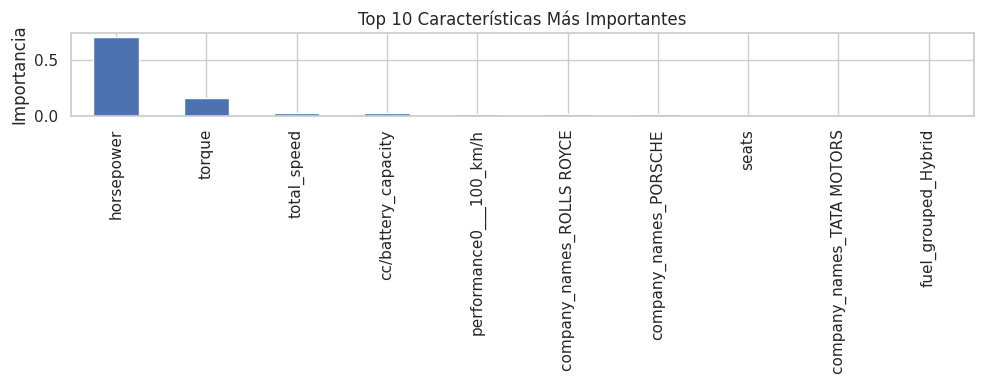

In [ ]:
# Interpretación básica del modelo (extracción de feature importances desde el Pipeline)
modelo_estimador = modelo_final.named_steps['model']
preprocesador = modelo_final.named_steps['preprocessor']

if hasattr(modelo_estimador, 'feature_importances_'):
  # Obtener los nombres de las columnas transformadas por el ColumnTransformer
  nombres_features = preprocesador.get_feature_names_out()
  # Limpiar los prefijos num__ y cat__ para facilitar la lectura
  nombres_limpios = [
      f.replace('num__', '').replace('cat__', '') for f in nombres_features
  ]

  importancias = pd.Series(
      modelo_estimador.feature_importances_, index=nombres_limpios
  ).sort_values(ascending=False)

  print('Importancia de las características principales:')
  display(importancias.head(10).round(3).to_frame('Importancia'))

  importancias.head(10).plot.bar(
      figsize=(10, 4), title='Top 10 Características Más Importantes'
  )
  plt.ylabel('Importancia')
  plt.tight_layout()
  plt.show()
else:
  print('El modelo elegido no proporciona feature_importances_.')

## Predicción de nuevos datos

Una vez seleccionado y evaluado el modelo, podemos utilizarlo para realizar predicciones sobre nuevos vehículos.

Vamos a crear tres vehículos ficticios con distintas especificaciones técnicas y utilizaremos el modelo seleccionado para estimar su precio de mercado.

Como los datos son nuevos, no conocemos sus precios reales preexistentes, pero el *pipeline* entrenado transformará automáticamente sus variables numéricas y categóricas para emitir la estimación en dólares ($).

In [ ]:
# 1. Creamos tres vehículos ficticios con las características originales
datos_nuevos = pd.DataFrame(
    [
        {
            'cc/battery_capacity': 3996,
            'horsepower': 510,
            'total_speed': 310,
            'performance0___100_km/h': 3.4,
            'seats': 2,
            'torque': 470,
            'company_names': 'Porsche',
            'fuel_grouped': 'Gasolina',
        },
        {
            'cc/battery_capacity': 1995,
            'horsepower': 190,
            'total_speed': 220,
            'performance0___100_km/h': 7.8,
            'seats': 5,
            'torque': 400,
            'company_names': 'BMW',
            'fuel_grouped': 'Diésel',
        },
        {
            'cc/battery_capacity': 1199,
            'horsepower': 83,
            'total_speed': 165,
            'performance0___100_km/h': 13.1,
            'seats': 5,
            'torque': 118,
            'company_names': 'Toyota',
            'fuel_grouped': 'Gasolina',
        },
    ],
    index=[
        'Coche A (Deportivo)',
        'Coche B (SUV / Berlina)',
        'Coche C (Utilitario)',
    ],
)

# 2. El Pipeline realiza automáticamente el escalado y el One-Hot Encoding de las categóricas
precios_estimados_log = modelo_final.predict(datos_nuevos)

# 3. Revertimos la escala logarítmica a dólares reales (USD)
precios_estimados_real = np.expm1(precios_estimados_log)

# 4. Mostramos la tabla con los resultados finales
resultados = pd.DataFrame(
    {'Precio estimado ($)': precios_estimados_real}, index=datos_nuevos.index
)

display(resultados.round(2))

,Precio estimado ($)
Coche A (Deportivo),146251.66
Coche B (SUV / Berlina),34670.90
Coche C (Utilitario),11825.32
